# Machine Learning Model Comparison – Student Academic Stress (Low / Medium / High)

**Input:** `Processed_Student_Stress_Data.csv` (the processed survey file).  
**Target:** `Stress_Level`  
**Leakage control:** `Stress_Item_1..12` and `Stress_Score` define the target, so they are **never** used as inputs.  
**Fair comparison:** same stratified 80:20 split (`random_state=42`), same preprocessing fitted on training data only (inside a `Pipeline`), same metrics for every model.

> These are conventional baselines only (not MC-ECII results). Non-diagnostic educational decision support.

## 1. Setup and upload the CSV

In [ ]:
import warnings; warnings.filterwarnings('ignore')
import os, io
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
os.makedirs('outputs', exist_ok=True)

In [ ]:
CSV_NAME = 'Processed_Student_Stress_Data.csv'

try:                                   # Google Colab: pick the file from your computer
    from google.colab import files
    if not os.path.exists(CSV_NAME):
        up = files.upload()
        CSV_NAME = list(up.keys())[0]
except ImportError:                    # running locally: expects the CSV next to the notebook
    pass

df = pd.read_csv(CSV_NAME)
print(df.shape)
df.head()

Saving Processed_Student_Stress_Data_Final.csv to Processed_Student_Stress_Data_Final.csv
(2066, 33)


,Student_ID,Age,Gender,State,Study_Hours,Class_Attendance,Exam_Frequency,Assignment_Load,Sleep_Hours,Physical_Exercise,...,Stress_Item_6,Stress_Item_7,Stress_Item_8,Stress_Item_9,Stress_Item_10,Stress_Item_11,Stress_Item_12,Stress_Score,Stress_Level,Screen_Flag
0,S0001,22,Female,Kerala,6,68,High,High,8,Low,...,4,5,4,3,4,2,3,45,High,0
1,S0002,25,Female,Tamil Nadu,7,82,Medium,High,6,Medium,...,3,3,3,4,2,4,3,41,High,0
2,S0003,21,Male,Telangana,7,79,High,High,6,Medium,...,4,4,5,4,4,3,2,42,High,0
3,S0004,21,Male,Delhi,2,84,High,Medium,6,Low,...,3,3,3,4,4,4,4,39,Medium,0
4,S0005,21,Female,Maharashtra,6,68,Medium,Low,6,Low,...,2,2,2,2,3,2,3,32,Low,0


In [ ]:
RANDOM_STATE      = 42
TEST_SIZE         = 0.20
USE_STATE         = False   # True = include 'State' as a feature
EXCLUDE_FLAGGED   = False   # True = drop the 405 rows where Social_Media_Use > Screen_Time
CV_FOLDS, CV_REPEATS = 5, 3
CLASS_ORDER = ['Low', 'Medium', 'High']

if EXCLUDE_FLAGGED:
    df = df[df['Screen_Flag'] == 0].reset_index(drop=True)

# columns that must NOT be inputs
leak_cols = [c for c in df.columns if c.startswith('Stress_Item_')] + ['Stress_Score', 'Stress_Level']
drop_cols = leak_cols + ['Student_ID', 'Screen_Flag'] + ([] if USE_STATE else ['State'])

X = df.drop(columns=drop_cols)
y = df['Stress_Level']
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

print('Rows used          :', len(df))
print('Numeric features   :', num_cols)
print('Categorical features:', cat_cols)
print('Leakage columns removed:', leak_cols)

Rows used          : 2066
Numeric features   : ['Age', 'Study_Hours', 'Class_Attendance', 'Sleep_Hours', 'Social_Media_Use', 'Screen_Time', 'Anxiety_Level']
Categorical features: ['Gender', 'Exam_Frequency', 'Assignment_Load', 'Physical_Exercise', 'Peer_Pressure', 'Family_Support', 'Family_Income_Level', 'Tuition', 'University_Type']
Leakage columns removed: ['Stress_Item_1', 'Stress_Item_2', 'Stress_Item_3', 'Stress_Item_4', 'Stress_Item_5', 'Stress_Item_6', 'Stress_Item_7', 'Stress_Item_8', 'Stress_Item_9', 'Stress_Item_10', 'Stress_Item_11', 'Stress_Item_12', 'Stress_Score', 'Stress_Level']


## 3. Quick data check

Stress_Level
Low       699
Medium    758
High      609
Name: count, dtype: int64 

Stress_Level
Low       33.8 %
Medium    36.7 %
High      29.5 %
Name: proportion, dtype: object


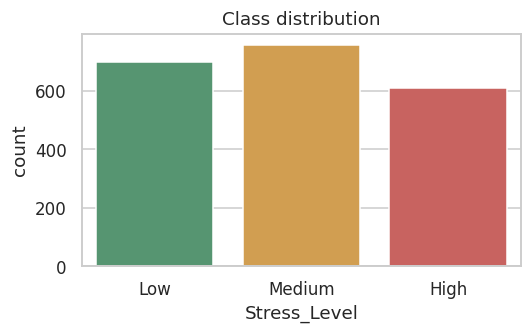

In [ ]:
print(y.value_counts().reindex(CLASS_ORDER), '\n')
print((y.value_counts(normalize=True).reindex(CLASS_ORDER)*100).round(1).astype(str) + ' %')
fig, ax = plt.subplots(figsize=(5,3.2))
sns.countplot(x=y, order=CLASS_ORDER, palette=['#4C9F70','#E6A23C','#D9534F'], ax=ax)
ax.set_title('Class distribution'); plt.tight_layout(); plt.savefig('outputs/class_distribution.png'); plt.show()

## 4. Train / test split and preprocessing

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Test:', X_test.shape)

# Fitted on training data only (inside each Pipeline) -> no leakage
preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])

Train: (1652, 16)  Test: (414, 16)


## 5. Define the models

In [ ]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'SVM (RBF)':           SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE),
    'Random Forest':       RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    'Decision Tree':       DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    'Gradient Boosting':   GradientBoostingClassifier(random_state=RANDOM_STATE),
    'KNN (k=15)':          KNeighborsClassifier(n_neighbors=15),
}
pipes = {n: Pipeline([('prep', preprocess), ('clf', m)]) for n, m in models.items()}

## 6. Train every model and evaluate on the held-out test set

In [ ]:
rows, preds, probas = [], {}, {}
for name, pipe in pipes.items():
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test)
    pr = pipe.predict_proba(X_test)
    preds[name] = p
    probas[name] = pr   # columns follow pipe.classes_ (alphabetical), as roc_auc_score expects
    rows.append({
        'Model': name,
        'Accuracy':        accuracy_score(y_test, p),
        'Precision (macro)': precision_score(y_test, p, average='macro'),
        'Recall (macro)':    recall_score(y_test, p, average='macro'),
        'Macro-F1':        f1_score(y_test, p, average='macro'),
        'Weighted-F1':     f1_score(y_test, p, average='weighted'),
        'ROC-AUC (OvR macro)': roc_auc_score(y_test, probas[name], multi_class='ovr',
                                             average='macro'),
    })
results = pd.DataFrame(rows).set_index('Model').sort_values('Macro-F1', ascending=False)
results.round(4)

,Accuracy,Precision (macro),Recall (macro),Macro-F1,Weighted-F1,ROC-AUC (OvR macro)
Model,,,,,,
Logistic Regression,0.6812,0.6875,0.6856,0.6865,0.6817,0.8369
SVM (RBF),0.6401,0.6498,0.6418,0.6452,0.6418,0.8011
Gradient Boosting,0.6329,0.6342,0.6351,0.6345,0.6320,0.8059
Random Forest,0.6087,0.6089,0.6119,0.6101,0.6066,0.7838
Decision Tree,0.5676,0.5739,0.5702,0.5718,0.5688,0.7320
KNN (k=15),0.4831,0.4827,0.4869,0.4846,0.4811,0.6916


## 7. Cross-validation on the training set (how stable is each model?)

In [ ]:
cv = RepeatedStratifiedKFold(n_splits=CV_FOLDS, n_repeats=CV_REPEATS, random_state=RANDOM_STATE)
cv_scores = {n: cross_val_score(p, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
             for n, p in pipes.items()}
cv_df = pd.DataFrame(cv_scores)
cv_summary = pd.DataFrame({'CV Macro-F1 (mean)': cv_df.mean(), 'CV Macro-F1 (std)': cv_df.std()})
results_full = results.join(cv_summary)
results_full.round(4)

,Accuracy,Precision (macro),Recall (macro),Macro-F1,Weighted-F1,ROC-AUC (OvR macro),CV Macro-F1 (mean),CV Macro-F1 (std)
Model,,,,,,,,
Logistic Regression,0.6812,0.6875,0.6856,0.6865,0.6817,0.8369,0.6315,0.0235
SVM (RBF),0.6401,0.6498,0.6418,0.6452,0.6418,0.8011,0.6005,0.0240
Gradient Boosting,0.6329,0.6342,0.6351,0.6345,0.6320,0.8059,0.5892,0.0239
Random Forest,0.6087,0.6089,0.6119,0.6101,0.6066,0.7838,0.5895,0.0207
Decision Tree,0.5676,0.5739,0.5702,0.5718,0.5688,0.7320,0.5203,0.0223
KNN (k=15),0.4831,0.4827,0.4869,0.4846,0.4811,0.6916,0.5156,0.0230


## 8. Charts

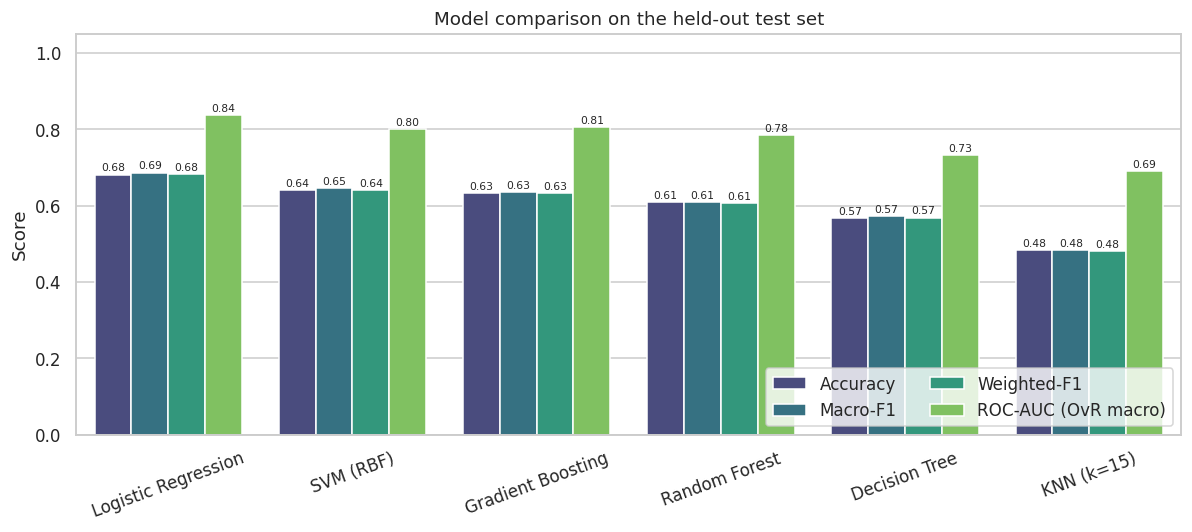

In [ ]:
# 8a. Grouped bar chart of the main metrics
metrics = ['Accuracy', 'Macro-F1', 'Weighted-F1', 'ROC-AUC (OvR macro)']
plot_df = results[metrics].reset_index().melt(id_vars='Model', var_name='Metric', value_name='Score')
fig, ax = plt.subplots(figsize=(11,5))
sns.barplot(data=plot_df, x='Model', y='Score', hue='Metric', palette='viridis', ax=ax,
            order=results.index)
ax.set_ylim(0, 1.05); ax.set_title('Model comparison on the held-out test set')
ax.set_xlabel(''); plt.xticks(rotation=20)
for c in ax.containers: ax.bar_label(c, fmt='%.2f', fontsize=7, padding=1)
ax.legend(loc='lower right', ncol=2); plt.tight_layout()
plt.savefig('outputs/model_comparison_bar.png'); plt.show()

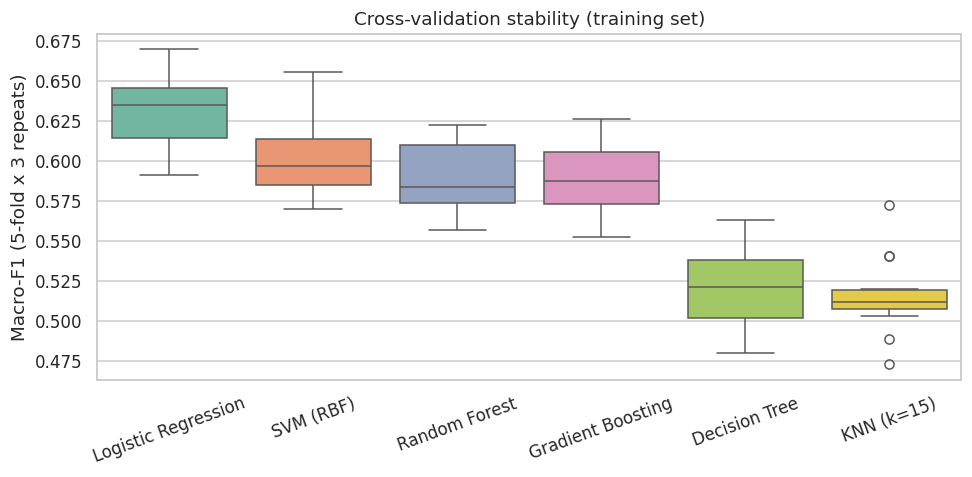

In [ ]:
# 8b. Cross-validation stability (box plot)
fig, ax = plt.subplots(figsize=(9,4.5))
order = cv_df.mean().sort_values(ascending=False).index
sns.boxplot(data=cv_df[order], palette='Set2', ax=ax)
ax.set_ylabel('Macro-F1 (5-fold x 3 repeats)'); ax.set_title('Cross-validation stability (training set)')
plt.xticks(rotation=20); plt.tight_layout(); plt.savefig('outputs/cv_boxplot.png'); plt.show()

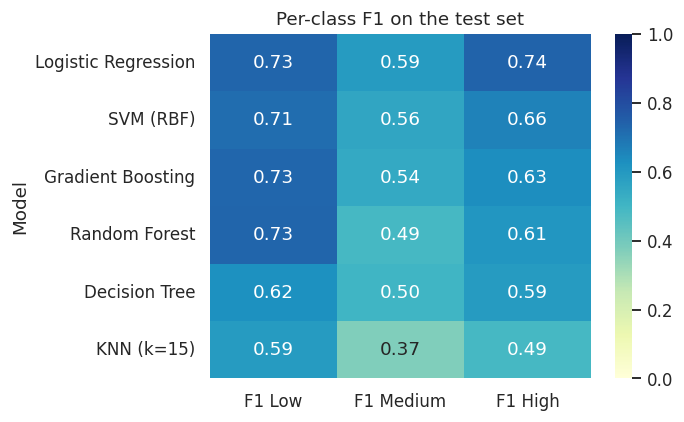

,F1 Low,F1 Medium,F1 High
Model,,,
Logistic Regression,0.7312,0.5928,0.7355
SVM (RBF),0.7148,0.5570,0.6638
Gradient Boosting,0.7298,0.5430,0.6307
Random Forest,0.7336,0.4883,0.6083
Decision Tree,0.6227,0.5000,0.5926
KNN (k=15),0.5923,0.3716,0.4898


In [ ]:
# 8c. Per-class F1 (does the model struggle on Low, Medium or High?)
pc = pd.DataFrame({n: f1_score(y_test, p, average=None, labels=CLASS_ORDER) for n, p in preds.items()},
                  index=CLASS_ORDER).T.loc[results.index]
pc.columns = [f'F1 {c}' for c in CLASS_ORDER]
fig, ax = plt.subplots(figsize=(6.5,4))
sns.heatmap(pc, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, ax=ax)
ax.set_title('Per-class F1 on the test set'); plt.tight_layout()
plt.savefig('outputs/per_class_f1.png'); plt.show()
pc.round(4)

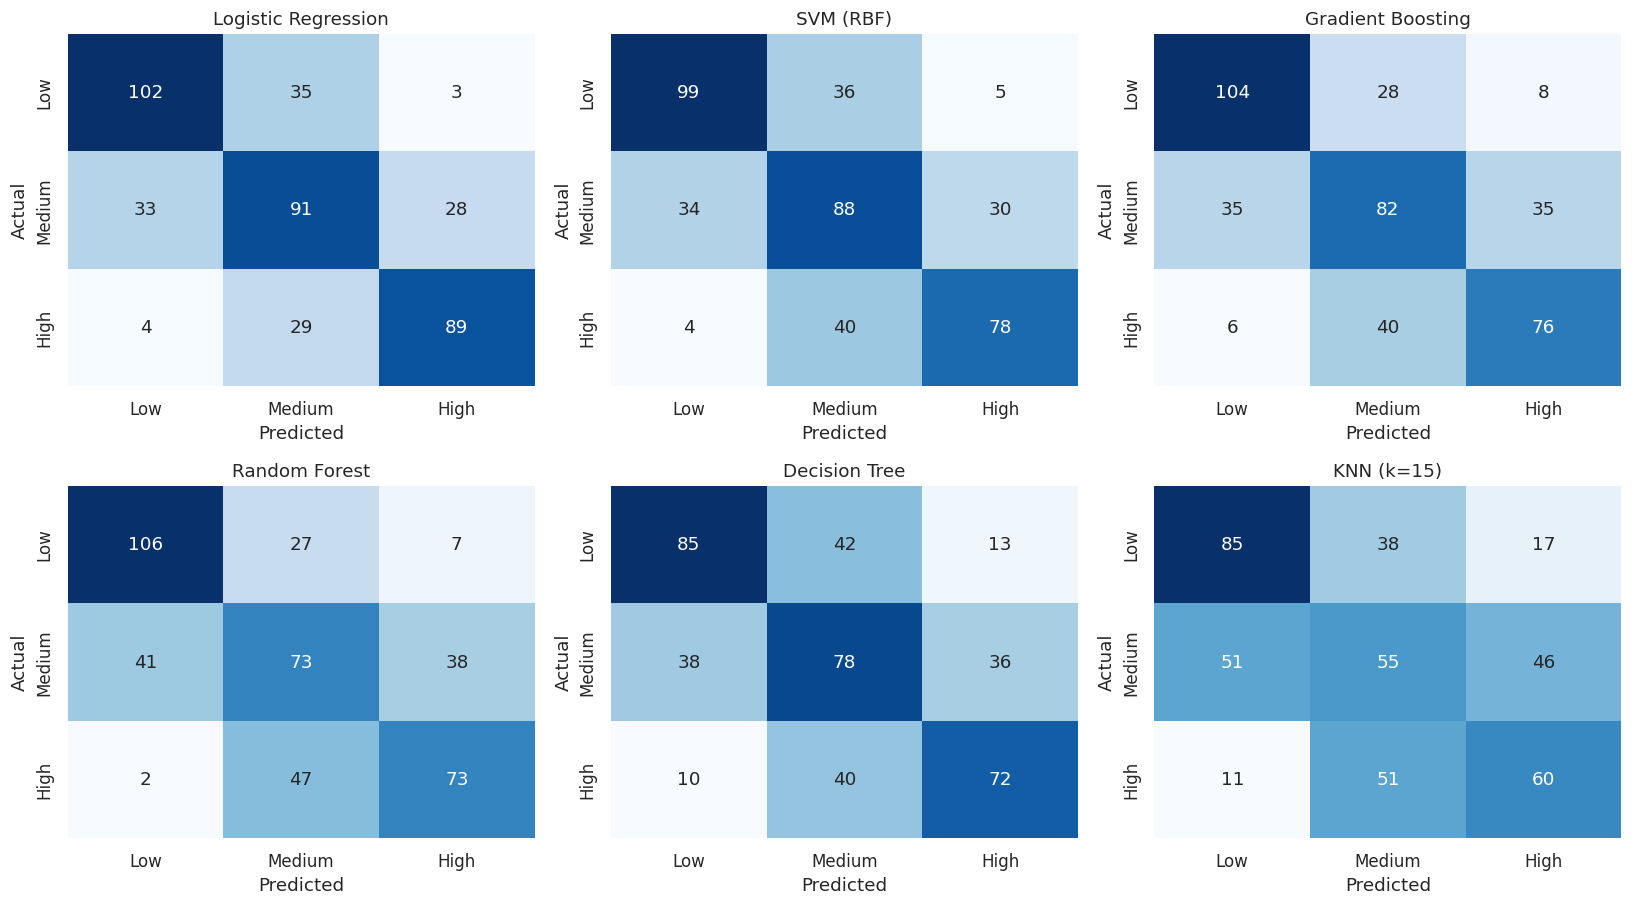

In [ ]:
# 8d. Confusion matrices for all models
n = len(preds); cols = 3; rows_ = int(np.ceil(n/cols))
fig, axes = plt.subplots(rows_, cols, figsize=(5*cols, 4.2*rows_))
for ax, name in zip(axes.ravel(), results.index):
    cm = confusion_matrix(y_test, preds[name], labels=CLASS_ORDER)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER)
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
for ax in axes.ravel()[n:]: ax.axis('off')
plt.tight_layout(); plt.savefig('outputs/confusion_matrices.png'); plt.show()

## 9. Which features matter? (Random Forest importance and Logistic Regression coefficients)

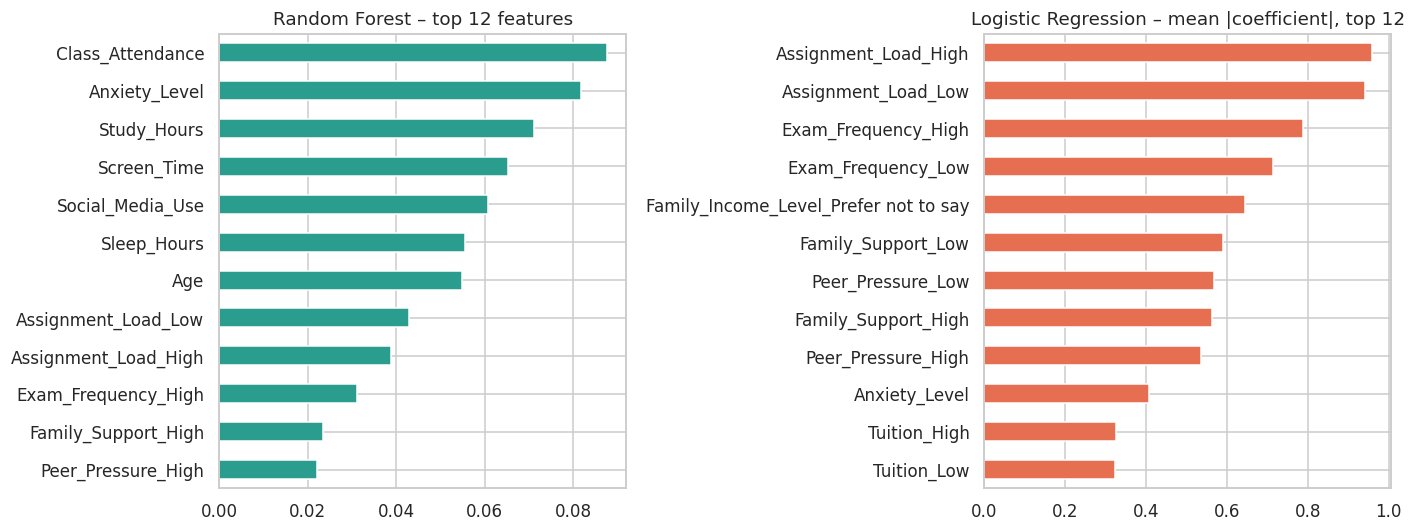

In [ ]:
feat_names = pipes['Random Forest'].named_steps['prep'].get_feature_names_out()
feat_names = [f.split('__')[1] for f in feat_names]

rf_imp = pd.Series(pipes['Random Forest'].named_steps['clf'].feature_importances_, index=feat_names)
lr_coef = pd.DataFrame(pipes['Logistic Regression'].named_steps['clf'].coef_,
                       columns=feat_names, index=pipes['Logistic Regression'].classes_)
lr_abs = lr_coef.abs().mean().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13,5))
rf_imp.sort_values().tail(12).plot.barh(ax=axes[0], color='#2a9d8f'); axes[0].set_title('Random Forest – top 12 features')
lr_abs.sort_values().tail(12).plot.barh(ax=axes[1], color='#e76f51'); axes[1].set_title('Logistic Regression – mean |coefficient|, top 12')
plt.tight_layout(); plt.savefig('outputs/feature_importance.png'); plt.show()

## 10. Final summary table, best model and detailed report

In [ ]:
best = results_full['Macro-F1'].idxmax()
print(f'Best model by test Macro-F1: {best}\n')
display(results_full.round(4).style.background_gradient(cmap='YlGn', subset=['Accuracy','Macro-F1','Weighted-F1','ROC-AUC (OvR macro)'])
        .format('{:.4f}'))
print('\nClassification report –', best)
print(classification_report(y_test, preds[best], labels=CLASS_ORDER, digits=3))

Best model by test Macro-F1: Logistic Regression



,Accuracy,Precision (macro),Recall (macro),Macro-F1,Weighted-F1,ROC-AUC (OvR macro),CV Macro-F1 (mean),CV Macro-F1 (std)
Model,,,,,,,,
Logistic Regression,0.6812,0.6875,0.6856,0.6865,0.6817,0.8369,0.6315,0.0235
SVM (RBF),0.6401,0.6498,0.6418,0.6452,0.6418,0.8011,0.6005,0.0240
Gradient Boosting,0.6329,0.6342,0.6351,0.6345,0.6320,0.8059,0.5892,0.0239
Random Forest,0.6087,0.6089,0.6119,0.6101,0.6066,0.7838,0.5895,0.0207
Decision Tree,0.5676,0.5739,0.5702,0.5718,0.5688,0.7320,0.5203,0.0223
KNN (k=15),0.4831,0.4827,0.4869,0.4846,0.4811,0.6916,0.5156,0.0230



Classification report – Logistic Regression
              precision    recall  f1-score   support

         Low      0.734     0.729     0.731       140
      Medium      0.587     0.599     0.593       152
        High      0.742     0.730     0.736       122

    accuracy                          0.681       414
   macro avg      0.688     0.686     0.687       414
weighted avg      0.682     0.681     0.682       414



In [ ]:
# majority-class baseline for context
maj = y_train.mode()[0]
print(f'Majority-class baseline accuracy: {(y_test == maj).mean():.3f} (always predicting "{maj}")')

Majority-class baseline accuracy: 0.367 (always predicting "Medium")


## 11. Save results and download

In [ ]:
results_full.round(4).to_csv('outputs/model_comparison_results.csv')
pc.round(4).to_csv('outputs/per_class_f1.csv')

import shutil
shutil.make_archive('model_comparison_outputs', 'zip', 'outputs')
try:
    from google.colab import files
    files.download('model_comparison_outputs.zip')
except ImportError:
    print('Saved to ./outputs and model_comparison_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>